# DS_Day01_08 – Hospital Resource Analysis

## HOSPITAL — WHICH DEPARTMENT NEEDS MORE RESOURCES?

**Industry:** Healthcare

### Objective
Analyze historical hospital data to understand patient demand,
staffing pressure, seasonal patterns, and department-level resource needs.

### Machine Learning Algorithm
Random Forest Regressor

#
Dataset / Objective
        ↓
Upload & Extract Dataset
        ↓
Load CSV Files
        ↓
Check Columns and Shapes
        ↓
[DATASET LIMITATION]  ← ADD HERE
        ↓
Data Cleaning & Preparation
        ↓
Monthly Data
        ↓
EDA
        ↓
Visualizations
        ↓
ANOVA
        ↓
Random Forest
        ↓
Insights
        ↓
Action Plan
        ↓
Conclusion

In [1]:
import zipfile
import os

with zipfile.ZipFile("archive (7).zip", "r") as zip_ref:
    zip_ref.extractall("hospital_data")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [2]:
os.listdir("hospital_data")

['clinic-healthcare-dataset']

In [3]:
import os

os.listdir("hospital_data/clinic-healthcare-dataset")

['appointments.csv',
 'prescriptions.csv',
 'patient_insurance.txt',
 'staff.csv',
 'treatments.csv',
 'patients.csv',
 'payments.csv',
 'doctors.csv',
 'clinics.csv']

In [4]:
import pandas as pd

path = "hospital_data/clinic-healthcare-dataset/"

appointments = pd.read_csv(path + "appointments.csv")
doctors = pd.read_csv(path + "doctors.csv")
staff = pd.read_csv(path + "staff.csv")
clinics = pd.read_csv(path + "clinics.csv")
treatments = pd.read_csv(path + "treatments.csv")

print("APPOINTMENTS")
print(appointments.columns.tolist())

print("\nDOCTORS")
print(doctors.columns.tolist())

print("\nSTAFF")
print(staff.columns.tolist())

print("\nCLINICS")
print(clinics.columns.tolist())

print("\nTREATMENTS")
print(treatments.columns.tolist())

APPOINTMENTS
['appointment_id', 'patient_id', 'doctor_id', 'clinic_id', 'appointment_date', 'status', 'reason_for_visit']

DOCTORS
['doctor_id', 'full_name', 'specialty', 'phone', 'email', 'clinic_id']

STAFF
['staff_id', 'full_name', 'role', 'clinic_id', 'phone', 'email']

CLINICS
['clinic_id', 'clinic_name', 'address', 'city', 'state', 'phone', 'opening_hours', 'clinic_type']

TREATMENTS
['treatment_id', 'appointment_id', 'treatment_type', 'treatment_cost', 'treatment_status']


In [5]:
print("APPOINTMENTS")
display(appointments.head())

print("\nDOCTORS")
display(doctors.head())

print("\nSTAFF")
display(staff.head())

print("\nCLINICS")
display(clinics.head())

print("\nTREATMENTS")
display(treatments.head())

APPOINTMENTS


,appointment_id,patient_id,doctor_id,clinic_id,appointment_date,status,reason_for_visit
0,A1,P13877,D86,C44,07/31/2025,Completed,Fever
1,A2,P3324,D129,C19,03/29/2025,Pending,Fever
2,A3,P12640,D326,C10,07/10/2025,Pending,Skin Allergy
3,A4,P387,D28,C30,06/13/2025,Cancelled,Heart Pain
4,A5,P14874,D241,C45,12/03/2025,Pending,Skin Allergy



DOCTORS


,doctor_id,full_name,specialty,phone,email,clinic_id
0,D1,Daniel Parks,Dermatology,(997) 703-4144,daniel.parks@hospital.com,C25
1,D2,Melissa Garrett,Dermatology,(537) 079-9288,melissa.garrett@hospital.com,C13
2,D3,Wayne Herrera,Pediatrics,(880) 785-0790,wayne.herrera@hospital.com,C9
3,D4,Debbie Tanner,Dermatology,(905) 797-7650,debbie.tanner@hospital.com,C45
4,D5,Beverly Lynn,Dermatology,(954) 211-1983,beverly.lynn@hospital.com,C36



STAFF


,staff_id,full_name,role,clinic_id,phone,email
0,S1,Caitlin Smith,Nurse,C49,(442) 119-5983,caitlin.smith@clinic.com
1,S2,John Gonzales,Receptionist,C2,(737) 260-0999,john.gonzales@clinic.com
2,S3,Kevin Palmer,Receptionist,C26,(263) 493-4210,kevin.palmer@clinic.com
3,S4,Jonathan Parker,Receptionist,C16,(236) 615-1329,jonathan.parker@clinic.com
4,S5,Kevin Li,Receptionist,C11,(314) 262-5410,kevin.li@clinic.com



CLINICS


,clinic_id,clinic_name,address,city,state,phone,opening_hours,clinic_type
0,C1,Medical Group Smithfurt,5634 Anderson Drives,East Mistybury,Washington,(698) 442-3059,9AM-5PM,Private
1,C2,Medical Group Mathewshaven,51735 Michael Loaf,North Juliafort,Oklahoma,(647) 141-2718,9AM-5PM,Public
2,C3,Family Health Clinic New Ritaview,0369 Scott Village,West Jennifertown,Colorado,(423) 942-6210,9AM-5PM,Private
3,C4,HealthCare Center Brettstad,038 Karla Lock Apt. 332,Robertbury,Missouri,(306) 551-4039,9AM-5PM,Private
4,C5,Medical Group Nataliestad,261 Robin Cliffs,Jamesville,Missouri,(010) 922-1520,9AM-5PM,Public



TREATMENTS


,treatment_id,appointment_id,treatment_type,treatment_cost,treatment_status
0,T1,A1,Surgery,1414.98,Pending
1,T2,A2,Surgery,1205.31,Pending
2,T3,A3,Surgery,445.09,Ongoing
3,T4,A4,Surgery,431.30,Completed
4,T5,A5,Therapy,1424.52,Completed


In [6]:
print("Appointments:", appointments.shape)
print("Doctors:", doctors.shape)
print("Staff:", staff.shape)
print("Clinics:", clinics.shape)
print("Treatments:", treatments.shape)

Appointments: (100000, 7)
Doctors: (500, 6)
Staff: (1000, 6)
Clinics: (50, 8)
Treatments: (100000, 5)


In [7]:
# Make copies so the original data is not changed
appointments_df = appointments.copy()
doctors_df = doctors.copy()
staff_df = staff.copy()

# Convert appointment date to datetime
appointments_df["appointment_date"] = pd.to_datetime(
    appointments_df["appointment_date"]
)

# Add month
appointments_df["Month"] = appointments_df["appointment_date"].dt.month

# Add month name
appointments_df["Month_Name"] = appointments_df["appointment_date"].dt.strftime("%B")

# Add doctor specialty to appointments
appointments_df = appointments_df.merge(
    doctors_df[["doctor_id", "specialty"]],
    on="doctor_id",
    how="left"
)

# Rename specialty as Department
appointments_df = appointments_df.rename(
    columns={"specialty": "Department"}
)

# Count staff in each clinic
staff_count = (
    staff_df.groupby("clinic_id")["staff_id"]
    .nunique()
    .reset_index()
)

staff_count = staff_count.rename(
    columns={"staff_id": "Staff_Count"}
)

# Add staff count to appointments
appointments_df = appointments_df.merge(
    staff_count,
    on="clinic_id",
    how="left"
)

# Display result
display(appointments_df.head())

,appointment_id,patient_id,doctor_id,clinic_id,appointment_date,status,reason_for_visit,Month,Month_Name,Department,Staff_Count
0,A1,P13877,D86,C44,2025-07-31,Completed,Fever,7,July,Pediatrics,24
1,A2,P3324,D129,C19,2025-03-29,Pending,Fever,3,March,Pediatrics,11
2,A3,P12640,D326,C10,2025-07-10,Pending,Skin Allergy,7,July,Pediatrics,24
3,A4,P387,D28,C30,2025-06-13,Cancelled,Heart Pain,6,June,Pediatrics,20
4,A5,P14874,D241,C45,2025-12-03,Pending,Skin Allergy,12,December,Pediatrics,20


In [8]:
monthly_data = (
    appointments_df
    .groupby(["Month", "Month_Name", "Department"])
    .agg(
        Patient_Volume=("patient_id", "nunique"),
        Staff_Count=("Staff_Count", "first")
    )
    .reset_index()
)

# Calculate patients handled per staff member
monthly_data["Patients_per_Staff"] = (
    monthly_data["Patient_Volume"] /
    monthly_data["Staff_Count"]
)

# Sort by month and department
monthly_data = monthly_data.sort_values(
    ["Month", "Department"]
)

display(monthly_data.head(20))

,Month,Month_Name,Department,Patient_Volume,Staff_Count,Patients_per_Staff
0,1,January,Cardiology,2592,27,96.000000
1,1,January,Dermatology,2630,11,239.090909
2,1,January,Pediatrics,2639,18,146.611111
3,2,February,Cardiology,2321,15,154.733333
4,2,February,Dermatology,2408,23,104.695652
5,2,February,Pediatrics,2351,23,102.217391
6,3,March,Cardiology,2587,25,103.480000
7,3,March,Dermatology,2884,13,221.846154
8,3,March,Pediatrics,2771,11,251.909091
9,4,April,Cardiology,2514,18,139.666667


In [9]:
Staff_Count=("Staff_Count", "first")

In [10]:
print("Missing values:")
print(monthly_data.isnull().sum())

print("\nDuplicate rows:")
print(monthly_data.duplicated().sum())

print("\nNumber of departments:")
print(monthly_data["Department"].nunique())

print("\nDepartments:")
print(monthly_data["Department"].unique())

print("\nMonths:")
print(monthly_data["Month_Name"].unique())

Missing values:
Month                 0
Month_Name            0
Department            0
Patient_Volume        0
Staff_Count           0
Patients_per_Staff    0
dtype: int64

Duplicate rows:
0

Number of departments:
3

Departments:
['Cardiology' 'Dermatology' 'Pediatrics']

Months:
['January' 'February' 'March' 'April' 'May' 'June' 'July' 'August'
 'September' 'October' 'November' 'December']


In [11]:
print("\nPatient volume summary:")
print(monthly_data["Patient_Volume"].describe())

print("\nStaff count summary:")
print(monthly_data["Staff_Count"].describe())


Patient volume summary:
count      36.000000
mean     2594.472222
std       126.639756
min      2321.000000
25%      2531.000000
50%      2597.000000
75%      2680.000000
max      2884.000000
Name: Patient_Volume, dtype: float64

Staff count summary:
count    36.000000
mean     20.500000
std       4.896063
min      11.000000
25%      17.750000
50%      21.000000
75%      24.000000
max      29.000000
Name: Staff_Count, dtype: float64


## Dataset Limitation

The available dataset contains appointment, doctor, staff, clinic,
and treatment information.

However, it does not directly provide:

- Average Treatment Duration
- Equipment Utilisation

Therefore, these variables were not artificially created.

The analysis focuses on the available demand and staffing indicators,
particularly Patient Volume, Staff Count, and Patients per Staff.

In [12]:
print("Missing values:")
print(monthly_data.isnull().sum())

print("\nDuplicate rows:")
print(monthly_data.duplicated().sum())

print("\nNumber of departments:")
print(monthly_data["Department"].nunique())

print("\nDepartments:")
print(monthly_data["Department"].unique())

print("\nNumber of months:")
print(monthly_data["Month"].nunique())

print("\nMonths:")
print(monthly_data["Month_Name"].unique())

Missing values:
Month                 0
Month_Name            0
Department            0
Patient_Volume        0
Staff_Count           0
Patients_per_Staff    0
dtype: int64

Duplicate rows:
0

Number of departments:
3

Departments:
['Cardiology' 'Dermatology' 'Pediatrics']

Number of months:
12

Months:
['January' 'February' 'March' 'April' 'May' 'June' 'July' 'August'
 'September' 'October' 'November' 'December']


In [13]:
print("\nPatient Volume:")
print(monthly_data["Patient_Volume"].describe())

print("\nStaff Count:")
print(monthly_data["Staff_Count"].describe())


Patient Volume:
count      36.000000
mean     2594.472222
std       126.639756
min      2321.000000
25%      2531.000000
50%      2597.000000
75%      2680.000000
max      2884.000000
Name: Patient_Volume, dtype: float64

Staff Count:
count    36.000000
mean     20.500000
std       4.896063
min      11.000000
25%      17.750000
50%      21.000000
75%      24.000000
max      29.000000
Name: Staff_Count, dtype: float64


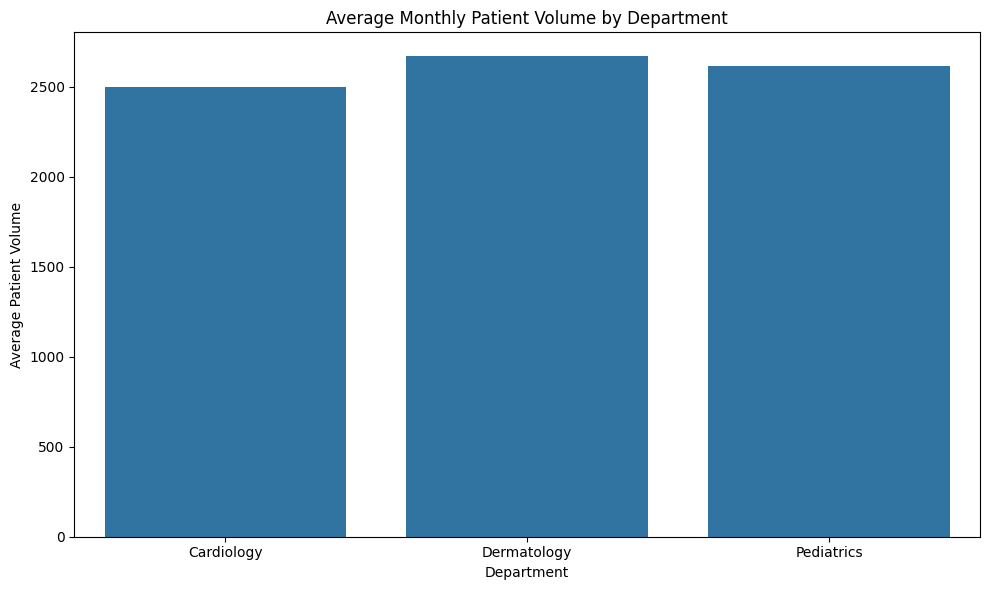

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=monthly_data,
    x="Department",
    y="Patient_Volume",
    errorbar=None
)

plt.title("Average Monthly Patient Volume by Department")
plt.xlabel("Department")
plt.ylabel("Average Patient Volume")

plt.tight_layout()
plt.show()

In [15]:
department_summary = (
    monthly_data
    .groupby("Department")
    .agg(
        Average_Patient_Volume=("Patient_Volume", "mean"),
        Average_Staff_Count=("Staff_Count", "mean"),
        Average_Patients_per_Staff=("Patients_per_Staff", "mean")
    )
    .round(2)
)

display(department_summary)


,Average_Patient_Volume,Average_Staff_Count,Average_Patients_per_Staff
Department,,,
Cardiology,2500.42,21.25,126.08
Dermatology,2667.92,19.33,147.91
Pediatrics,2615.08,20.92,132.70


In [16]:
department_summary = (
    monthly_data
    .groupby("Department")
    .agg(
        Average_Patient_Volume=("Patient_Volume", "mean"),
        Average_Staff_Count=("Staff_Count", "mean"),
        Average_Patients_per_Staff=("Patients_per_Staff", "mean")
    )
    .round(2)
)

display(department_summary)

,Average_Patient_Volume,Average_Staff_Count,Average_Patients_per_Staff
Department,,,
Cardiology,2500.42,21.25,126.08
Dermatology,2667.92,19.33,147.91
Pediatrics,2615.08,20.92,132.70


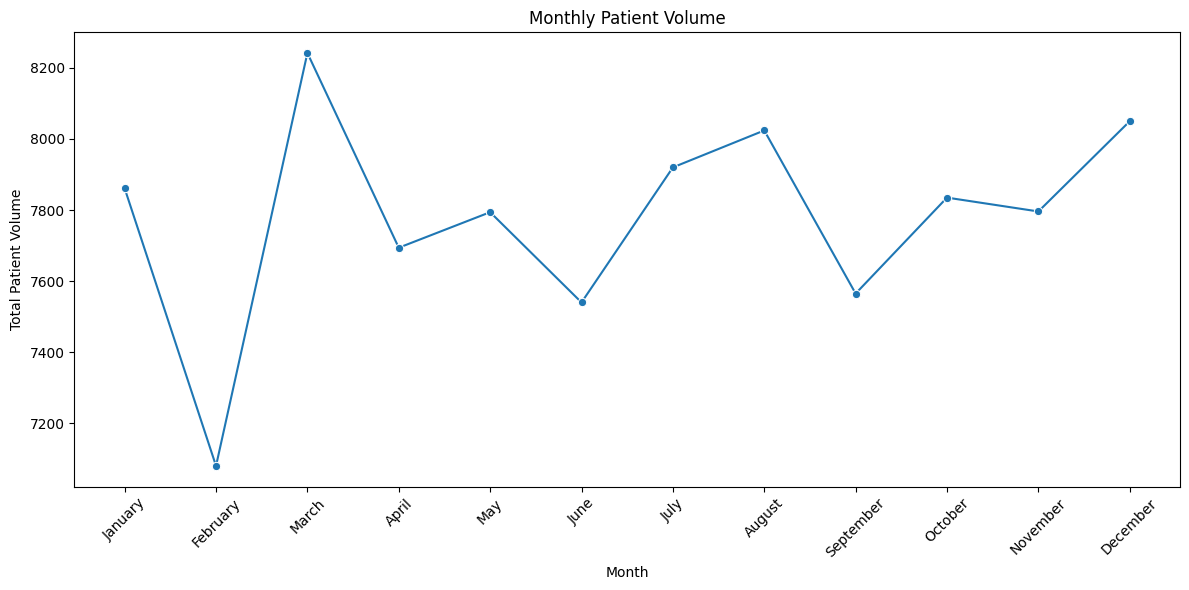

In [17]:
monthly_total = (
    monthly_data
    .groupby(["Month", "Month_Name"])["Patient_Volume"]
    .sum()
    .reset_index()
    .sort_values("Month")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_total,
    x="Month_Name",
    y="Patient_Volume",
    marker="o"
)

plt.title("Monthly Patient Volume")
plt.xlabel("Month")
plt.ylabel("Total Patient Volume")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

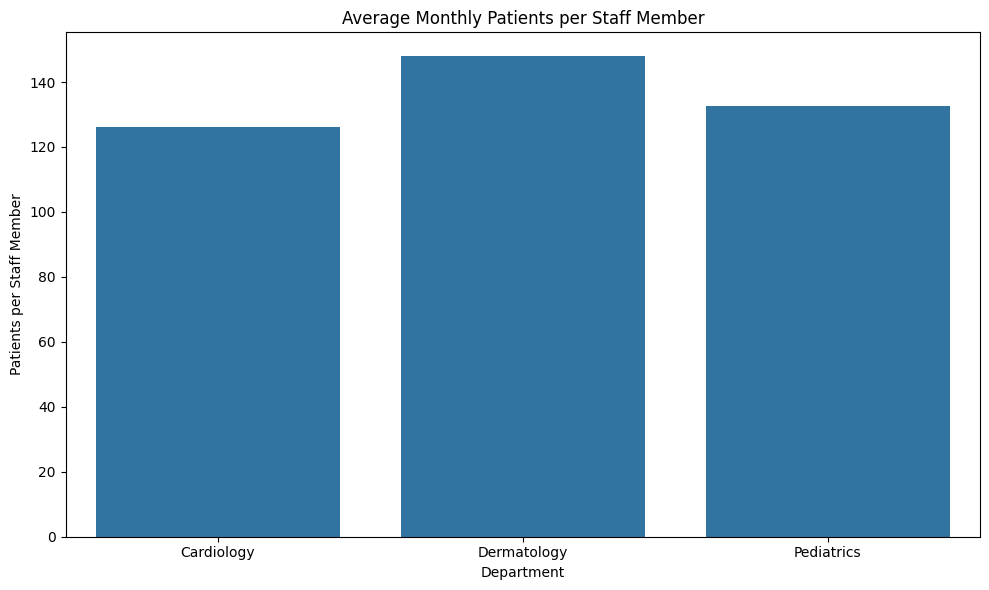

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=monthly_data,
    x="Department",
    y="Patients_per_Staff",
    errorbar=None
)

plt.title("Average Monthly Patients per Staff Member")
plt.xlabel("Department")
plt.ylabel("Patients per Staff Member")

plt.tight_layout()
plt.show()

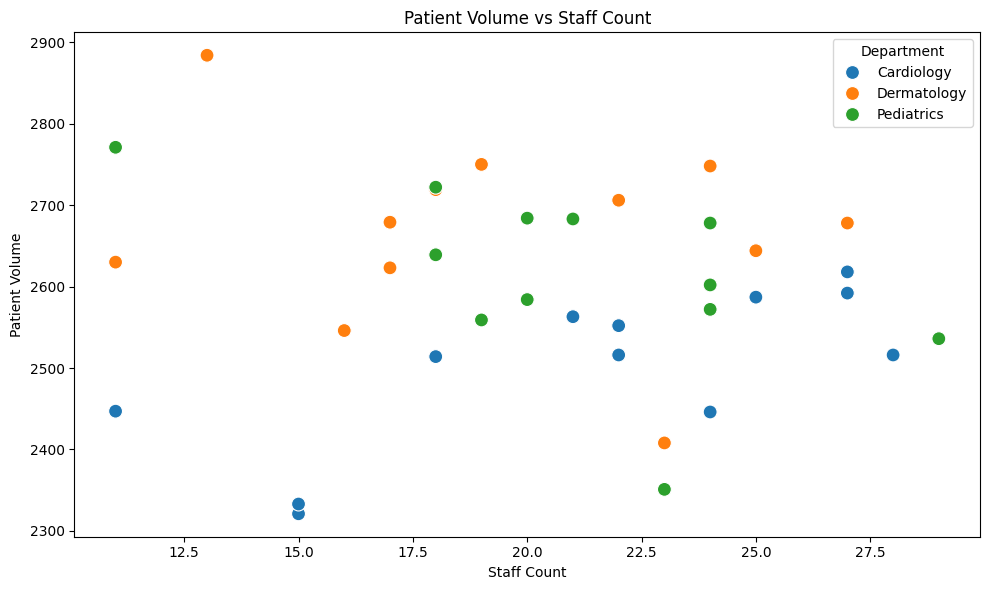

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=monthly_data,
    x="Staff_Count",
    y="Patient_Volume",
    hue="Department",
    s=100
)

plt.title("Patient Volume vs Staff Count")
plt.xlabel("Staff Count")
plt.ylabel("Patient Volume")

plt.tight_layout()
plt.show()

In [20]:
resource_summary = (
    monthly_data
    .groupby("Department")
    .agg(
        Avg_Patient_Volume=("Patient_Volume", "mean"),
        Avg_Staff_Count=("Staff_Count", "mean"),
        Avg_Patients_per_Staff=("Patients_per_Staff", "mean"),
        Max_Patient_Volume=("Patient_Volume", "max"),
        Min_Staff_Count=("Staff_Count", "min")
    )
    .round(2)
)

display(resource_summary)

,Avg_Patient_Volume,Avg_Staff_Count,Avg_Patients_per_Staff,Max_Patient_Volume,Min_Staff_Count
Department,,,,,
Cardiology,2500.42,21.25,126.08,2618,11
Dermatology,2667.92,19.33,147.91,2884,11
Pediatrics,2615.08,20.92,132.70,2771,11


In [21]:
pressure = resource_summary.sort_values(
    "Avg_Patients_per_Staff",
    ascending=False
)

display(pressure)

,Avg_Patient_Volume,Avg_Staff_Count,Avg_Patients_per_Staff,Max_Patient_Volume,Min_Staff_Count
Department,,,,,
Dermatology,2667.92,19.33,147.91,2884,11
Pediatrics,2615.08,20.92,132.70,2771,11
Cardiology,2500.42,21.25,126.08,2618,11


In [22]:
from scipy.stats import f_oneway

departments = monthly_data["Department"].unique()

groups = [
    monthly_data[
        monthly_data["Department"] == dept
    ]["Patients_per_Staff"]
    for dept in departments
]

f_stat, p_value = f_oneway(*groups)

print("F-statistic:", round(f_stat, 4))
print("p-value:", round(p_value, 4))

F-statistic: 0.8721
p-value: 0.4275


In [23]:
if p_value < 0.05:
    print("There is a statistically significant difference in staff pressure between departments.")
else:
    print("There is no statistically significant difference in staff pressure between departments.")

There is no statistically significant difference in staff pressure between departments.


In [24]:
ml_data = monthly_data.copy()

# Convert department into numerical columns
ml_data = pd.get_dummies(
    ml_data,
    columns=["Department"],
    drop_first=True
)

# Select features
X = ml_data.drop(
    columns=[
        "Patient_Volume",
        "Month_Name"
    ]
)

y = ml_data["Patient_Volume"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Patient_Volume")

Features:
['Month', 'Staff_Count', 'Patients_per_Staff', 'Department_Dermatology', 'Department_Pediatrics']

Target:
Patient_Volume


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 28
Testing samples: 8


In [26]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
y_pred = rf_model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred.round(2))

Actual values:
[2684 2719 2572 2516 2623 2678 2552 2516]

Predicted values:
[2663.11 2626.5  2609.71 2580.57 2600.1  2606.65 2627.08 2552.26]


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-----------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Model Evaluation
-----------------
MAE : 52.66
RMSE: 58.26
R²  : 0.391


In [29]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,Patients_per_Staff,0.333675
0,Month,0.252361
1,Staff_Count,0.246356
3,Department_Dermatology,0.108130
4,Department_Pediatrics,0.059478


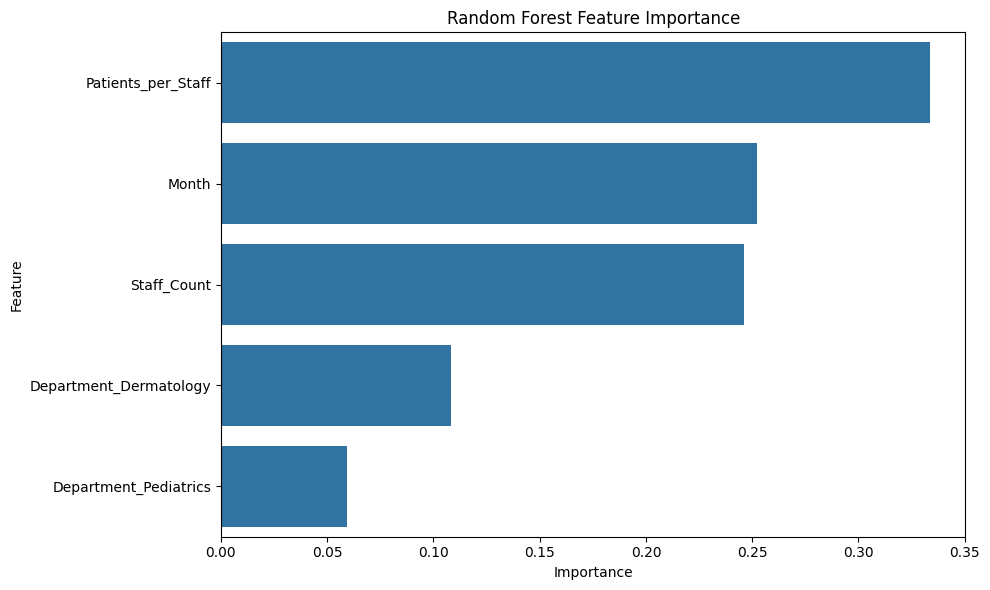

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [31]:
monthly_data.to_csv(
    "DS_Day01_08_Hospital_Analysis.csv",
    index=False
)

print("Final analysis dataset saved successfully!")

Final analysis dataset saved successfully!


## Department Summary

This section compares average patient volume, average staff count,
and patients-per-staff ratio across departments.

In [32]:
department_summary = (
    monthly_data
    .groupby("Department")
    .agg(
        Average_Patient_Volume=("Patient_Volume", "mean"),
        Average_Staff_Count=("Staff_Count", "mean"),
        Average_Patients_per_Staff=("Patients_per_Staff", "mean")
    )
    .round(2)
)

display(department_summary)

,Average_Patient_Volume,Average_Staff_Count,Average_Patients_per_Staff
Department,,,
Cardiology,2500.42,21.25,126.08
Dermatology,2667.92,19.33,147.91
Pediatrics,2615.08,20.92,132.70


## Highest Demand Department


In [33]:
highest_demand = department_summary["Average_Patient_Volume"].idxmax()

print("Department with highest average patient volume:", highest_demand)

Department with highest average patient volume: Dermatology


## Highest Staffing Pressure

In [34]:
highest_pressure = department_summary["Average_Patients_per_Staff"].idxmax()

print("Department with highest patients-per-staff pressure:", highest_pressure)

Department with highest patients-per-staff pressure: Dermatology


## Monthly Demand Analysis

In [35]:
busiest_month = (
    monthly_total.loc[
        monthly_total["Patient_Volume"].idxmax(),
        "Month_Name"
    ]
)

highest_month_volume = monthly_total["Patient_Volume"].max()

print("Busiest month:", busiest_month)
print("Total patient volume:", highest_month_volume)

Busiest month: March
Total patient volume: 8242


## Highest Patients-per-Staff Periods

In [36]:
top_pressure = monthly_data.sort_values(
    "Patients_per_Staff",
    ascending=False
).head(10)

display(
    top_pressure[
        [
            "Month_Name",
            "Department",
            "Patient_Volume",
            "Staff_Count",
            "Patients_per_Staff"
        ]
    ]
)

,Month_Name,Department,Patient_Volume,Staff_Count,Patients_per_Staff
8,March,Pediatrics,2771,11,251.909091
1,January,Dermatology,2630,11,239.090909
24,September,Cardiology,2447,11,222.454545
7,March,Dermatology,2884,13,221.846154
25,September,Dermatology,2546,16,159.125000
19,July,Dermatology,2679,17,157.588235
15,June,Cardiology,2333,15,155.533333
3,February,Cardiology,2321,15,154.733333
16,June,Dermatology,2623,17,154.294118
23,August,Pediatrics,2722,18,151.222222


## Random Forest – Actual vs Predicted

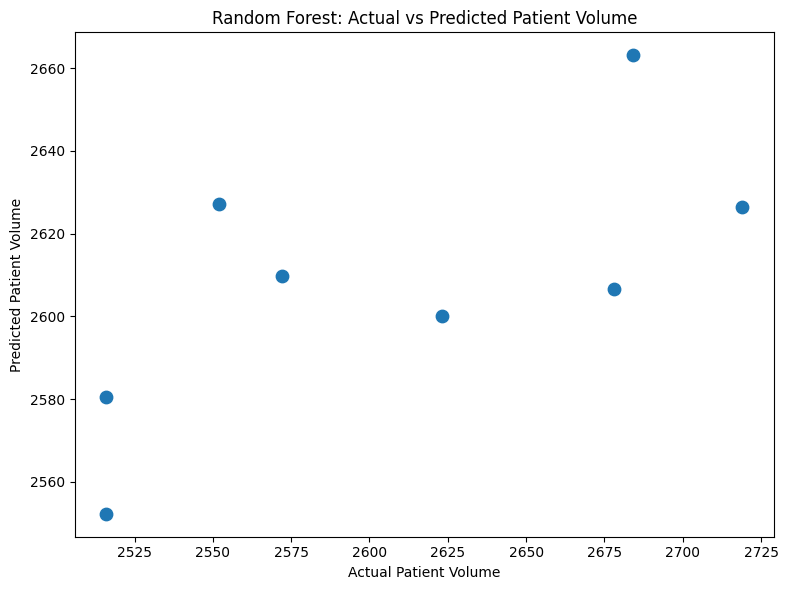

In [37]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred, s=80)

plt.xlabel("Actual Patient Volume")
plt.ylabel("Predicted Patient Volume")
plt.title("Random Forest: Actual vs Predicted Patient Volume")

plt.tight_layout()
plt.show()

## Random Forest Model Evaluation

In [38]:
print("Random Forest Model Evaluation")
print("-" * 35)
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")

Random Forest Model Evaluation
-----------------------------------
MAE  : 52.66
RMSE : 58.26
R²   : 0.391


## Random Forest Feature Importance

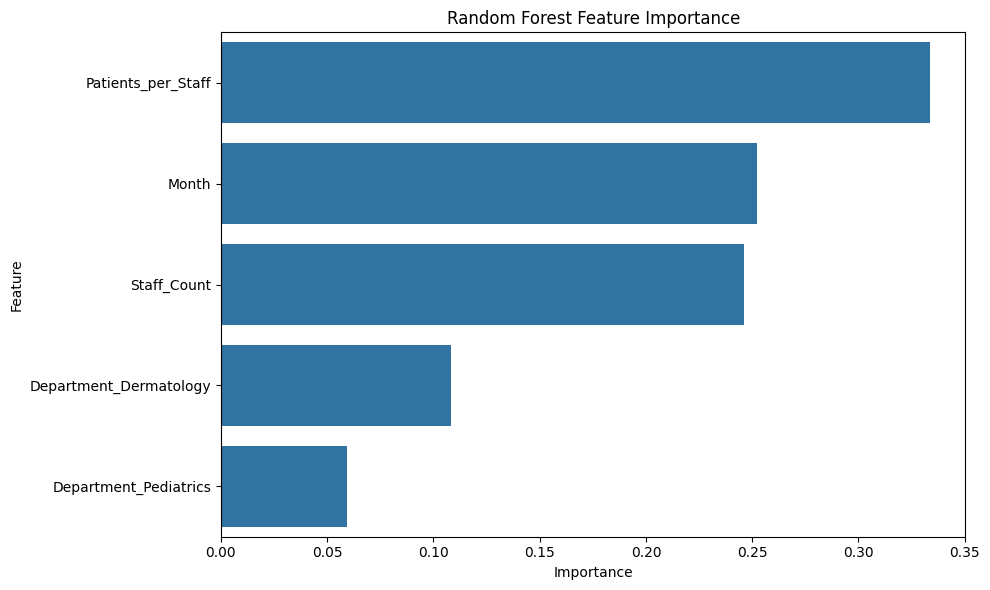

In [39]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

#Insights

1. The analysis contains 36 monthly department-level observations,
   representing 12 months across 3 departments.

2. Monthly department-level patient volume ranges from approximately
   2,321 to 2,884 patients.

3. The average monthly patient volume is approximately 2,594 patients,
   while the average staff count is approximately 20.5.

4. Patients-per-Staff provides an indicator of staffing pressure and
   helps identify periods where patient demand is high relative to
   available staff.

5. The ANOVA test produced an F-statistic of 0.8721 and a p-value of
   0.4275. Therefore, no statistically significant difference in mean
   Patients-per-Staff was detected between departments at the 5% level.

6. The Random Forest model achieved an MAE of 52.66, RMSE of 58.26,
   and R² of 0.391.

7. Patients_per_Staff, Month, and Staff_Count were the most influential
   features according to the Random Forest feature importance.

In [40]:
monthly_data.to_csv(
    "DS_Day01_08_Hospital_Analysis.csv",
    index=False
)

print("Final analysis dataset saved successfully!")

Final analysis dataset saved successfully!
